## Neural Network Feature Ablation

This experiment determines the impact of certain design choices of our neural network for options pricing predictions under the Black-Scholes model. Specifically, it tests for the effectiveness of:
- Feature engineering, from absolute prices $(S, K)$ to log-moneyness $\log{\frac{S}{K}}.$
- Standardization of input space and output space $X, y,$ and log-transform of our target (hence predicting $\log{\frac{C}{K}}$ instead of $\frac{C}{K}.$
- Model architecture (4 --> 128 --> 128 --> 64 --> 1) against a reduced variant (4 --> 128 --> 128 --> 1)
- Hybrid loss, comparing a weighted sum of MSE and y * MSE against standard MSE.

We begin with a baseline model incorporating all features above, before performing controlled ablations by removing a single feature at any moment in time while keeping all others constant.


The baseline model is trained on the following dataset. For reproducibility, we retrain the model inside the notebook.
- 100,000 training samples, 10,000 eval samples.
- $\log{\frac{S}{K}} \in [-2, 2]$
- $T \in [0.1, 2],$ with a log-normal distribution.
- $\sigma \in (0.1, 0.5)$
- $r$ set constant at $r = 0.02.$

For implementation details, reference `constants.py`.
 

In [1]:
import sys

sys.path.append("..")

from src.constants import NN_MODEL_PATH
from src.data.dataset_generator import DataConfig, generate_bundle
from src.eval.validate import compute_metrics, plot_validation_results, preprocess_test_data, print_metrics_report
from src.training.train_nn import predict, train, set_seed, get_device
import pandas as pd

In [2]:
# training is done on default hyperparams.
cfg = DataConfig()
dataset_bundle = generate_bundle(cfg)
set_seed(42)
device = get_device(use_cpu=True)

X_train, y_train = dataset_bundle.train.X, dataset_bundle.train.y_call
X_val, y_val = dataset_bundle.val.X, dataset_bundle.val.y_call
    
nn_model, norm_params = train(
    X_train, y_train, X_val, y_val,
    device=device,
    patience=25,
    epochs=400,
)

Epoch 0, Training Loss: 0.87839770, Eval Loss: 0.77281576
Epoch 10, Training Loss: 0.26086006, Eval Loss: 0.23006313
Epoch 20, Training Loss: 0.10896422, Eval Loss: 0.10069548
Epoch 30, Training Loss: 0.04947736, Eval Loss: 0.04822300
Epoch 40, Training Loss: 0.04248786, Eval Loss: 0.04154200
Epoch 50, Training Loss: 0.03112861, Eval Loss: 0.03042949
Epoch 60, Training Loss: 0.02625081, Eval Loss: 0.02545092
Epoch 70, Training Loss: 0.02148022, Eval Loss: 0.02081683
Epoch 80, Training Loss: 0.01749942, Eval Loss: 0.01686755
Epoch 90, Training Loss: 0.01404528, Eval Loss: 0.01348661
Epoch 100, Training Loss: 0.01117307, Eval Loss: 0.01065316
Epoch 110, Training Loss: 0.00891439, Eval Loss: 0.00847348
Epoch 120, Training Loss: 0.00730735, Eval Loss: 0.00693787
Epoch 130, Training Loss: 0.00619703, Eval Loss: 0.00589136
Epoch 140, Training Loss: 0.00535545, Eval Loss: 0.00507409
Epoch 150, Training Loss: 0.00469479, Eval Loss: 0.00444504
Epoch 160, Training Loss: 0.00416378, Eval Loss: 0.

Now we evaluate this control on a few metrics:
- MAE
- RMSE
- Heatmap of rel. error across $T$ and log-moneyness.

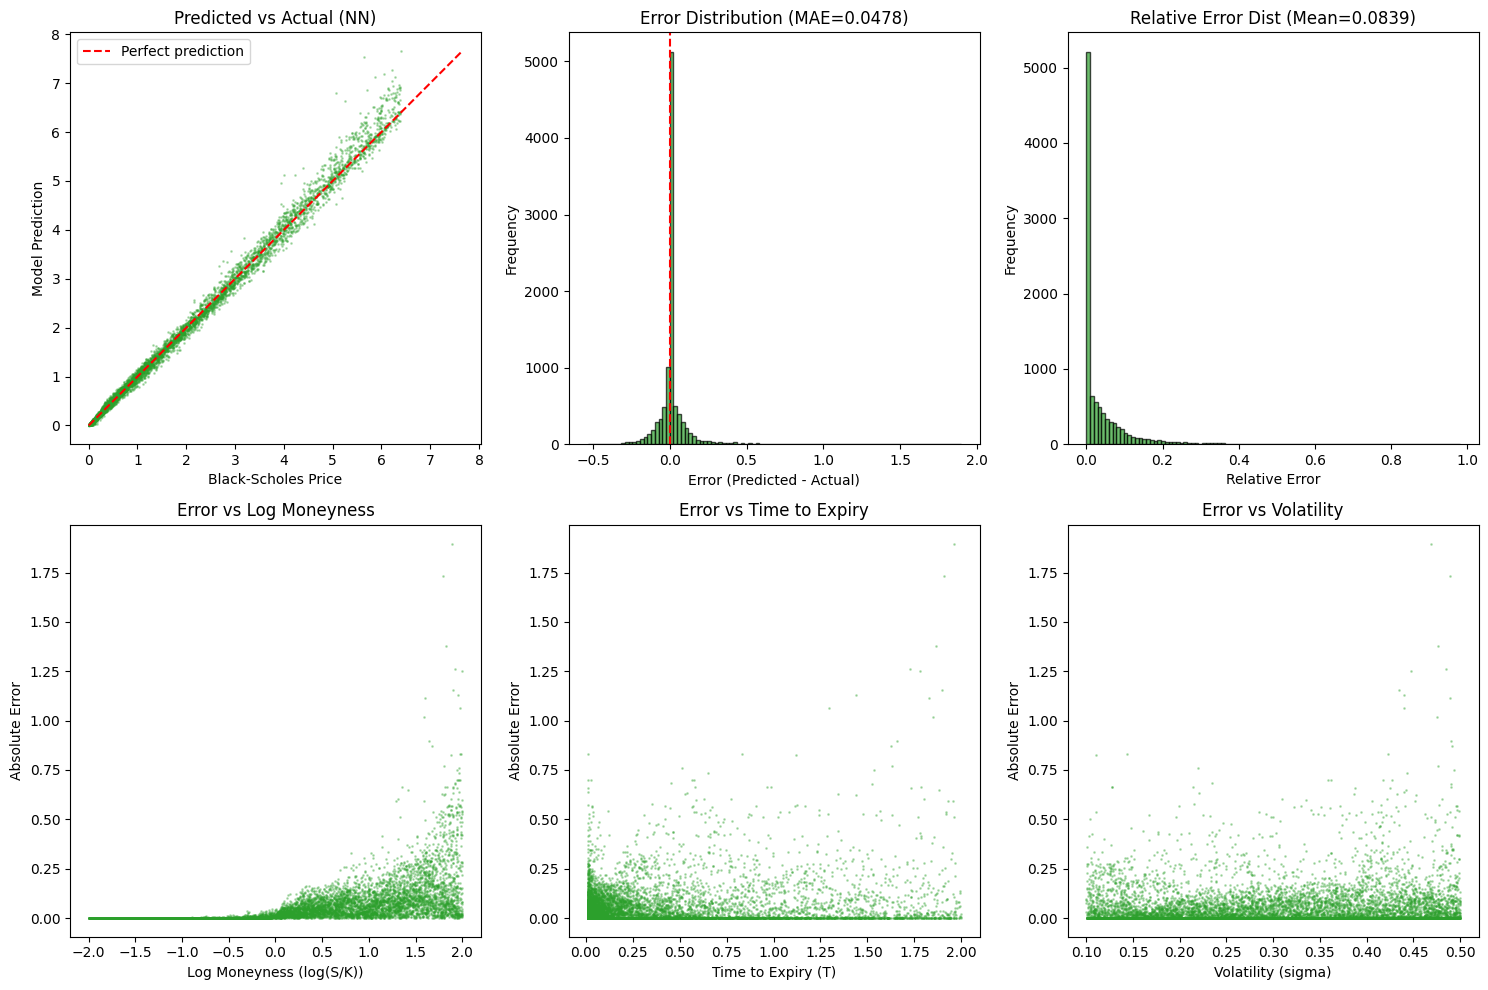

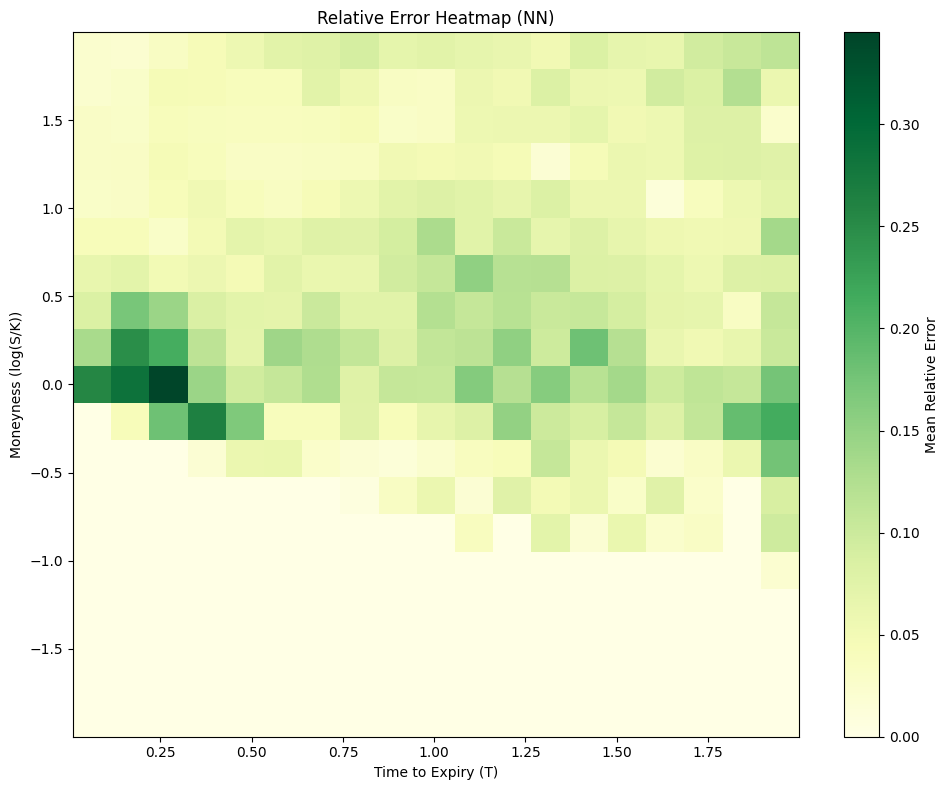


BASELINE (LOG-MONEYNESS, 4-128-128-64-1) MODEL VALIDATION REPORT
Mean Absolute Error (MAE):     0.047767
Root Mean Square Error (RMSE): 0.107489
Max Absolute Error:            1.896842
--------------------------------------------------
Mean Relative Error:           8.3875%
Median Relative Error:         4.8231%



In [3]:
EVAL_STYLE = {'color': 'tab:green', 'cmap': 'YlGn', 'suffix': '', 'display_name': 'NN'}

X_test_raw, y_test = dataset_bundle.test.X, dataset_bundle.test.y_call
X_test, _ = preprocess_test_data(X_test_raw)
y_pred = predict(nn_model, X_test, norm_params, device="cpu")

def eval(label="Baseline"):
    metrics = compute_metrics(y_test,
                          y_pred,
                          min_value_threshold=0.01)

    plot_validation_results(X_test_raw,
                        y_test,
                        y_pred,
                        metrics,
                        EVAL_STYLE,
                        save_dir=None)

    print_metrics_report(metrics, label)

eval("Baseline (log-moneyness, 4-128-128-64-1)")

As these are benchmark numbers, no further discussion is necessary, although it is worth noting an increase in absolute error over log-moneyness, resulting in a "fan"-shaped error distribution, as shown in the bottom-left plot. This could possibly imply some form of heteroskedasticity as $C$ increases.

### Log-Moneyness Feature Engineering

Now we train a model on the exact same dataset (refer to the parameters above), except we pass the raw strike price and stock price $S, K$ as inputs, instead of log moneyness. 

**Note: the structure of the model changes to 5 --> 128 --> 128 --> 64 --> 1 due to the increased number of inputs. No other change to model architecture was made.**

In [4]:
from src.models.bs_model import BSModel

cfg = cfg.replace(feature_mode="raw")

RAW_MODEL_ARCHITECTURE = [5, 128, 128, 64, 1]
raw_model = BSModel(layers=RAW_MODEL_ARCHITECTURE)

raw_bundle = generate_bundle(cfg)

X_train, y_train = raw_bundle.train.X, raw_bundle.train.y_call
X_val, y_val = raw_bundle.val.X, raw_bundle.val.y_call

set_seed(42)

raw_model, norm_params = train(
    X_train, y_train, X_val, y_val,
    device=device,
    patience=25,
    epochs=400,
    model=raw_model
)

Epoch 0, Training Loss: 0.99117768, Eval Loss: 0.91774237
Epoch 10, Training Loss: 0.47505376, Eval Loss: 0.43311778
Epoch 20, Training Loss: 0.19367416, Eval Loss: 0.18248603
Epoch 30, Training Loss: 0.12713318, Eval Loss: 0.11777563
Epoch 40, Training Loss: 0.08534667, Eval Loss: 0.08116592
Epoch 50, Training Loss: 0.05929457, Eval Loss: 0.05691343
Epoch 60, Training Loss: 0.04921669, Eval Loss: 0.04788120
Epoch 70, Training Loss: 0.04264764, Eval Loss: 0.04133606
Epoch 80, Training Loss: 0.03633012, Eval Loss: 0.03524892
Epoch 90, Training Loss: 0.03138900, Eval Loss: 0.03043109
Epoch 100, Training Loss: 0.02713421, Eval Loss: 0.02621033
Epoch 110, Training Loss: 0.02344171, Eval Loss: 0.02260108
Epoch 120, Training Loss: 0.02039964, Eval Loss: 0.01957360
Epoch 130, Training Loss: 0.01778015, Eval Loss: 0.01698107
Epoch 140, Training Loss: 0.01550037, Eval Loss: 0.01475977
Epoch 150, Training Loss: 0.01354887, Eval Loss: 0.01287416
Epoch 160, Training Loss: 0.01188388, Eval Loss: 0.

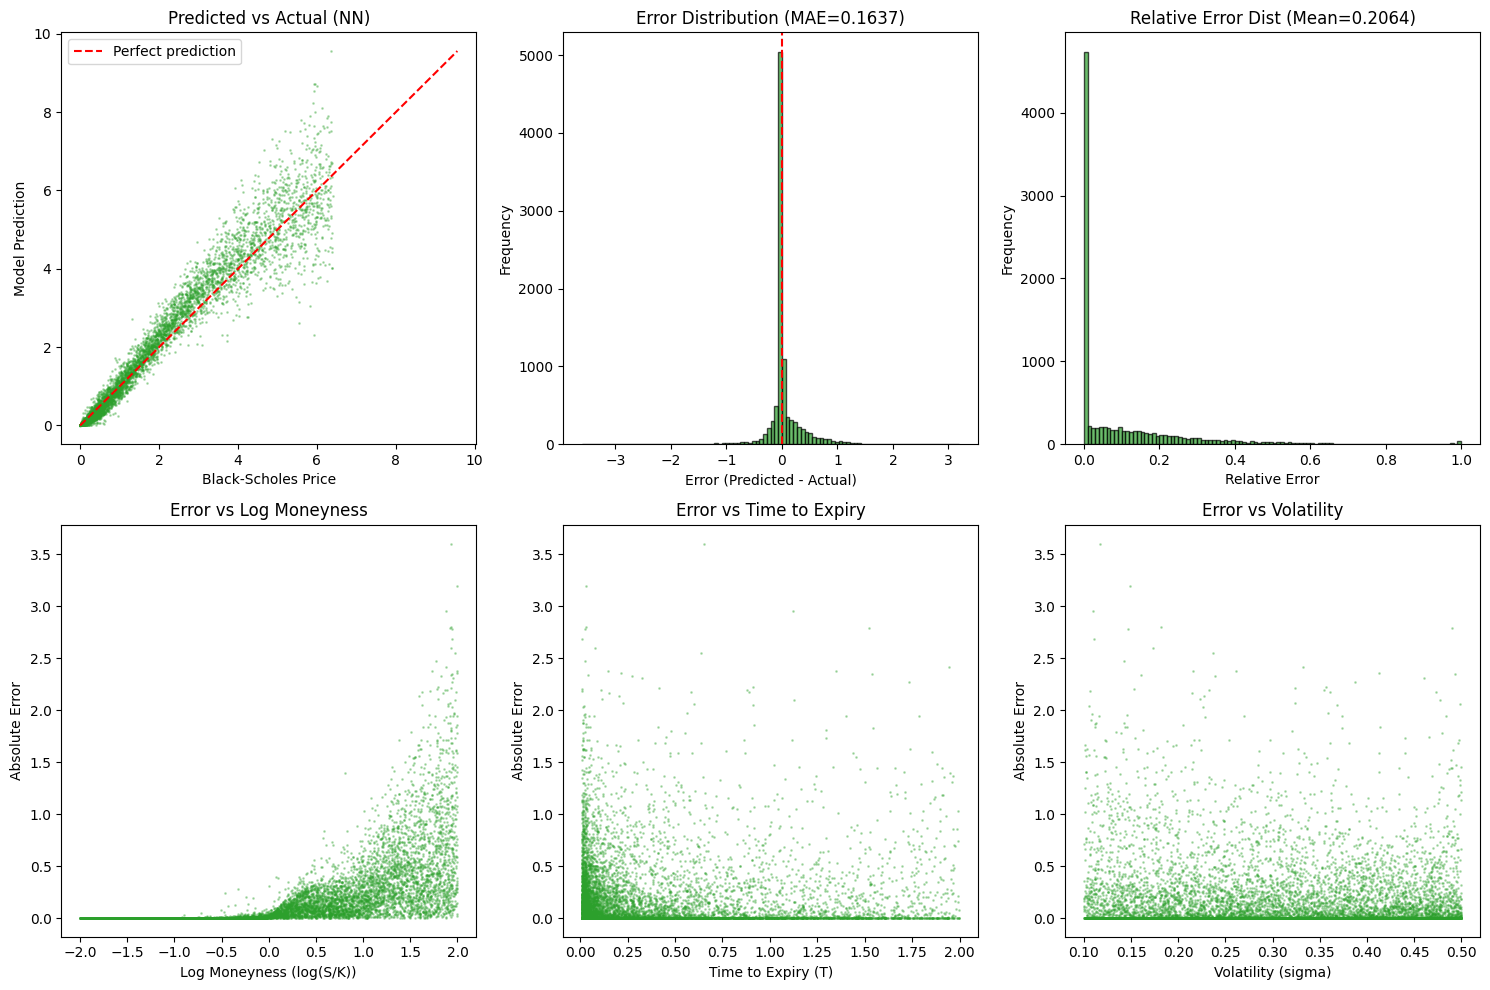

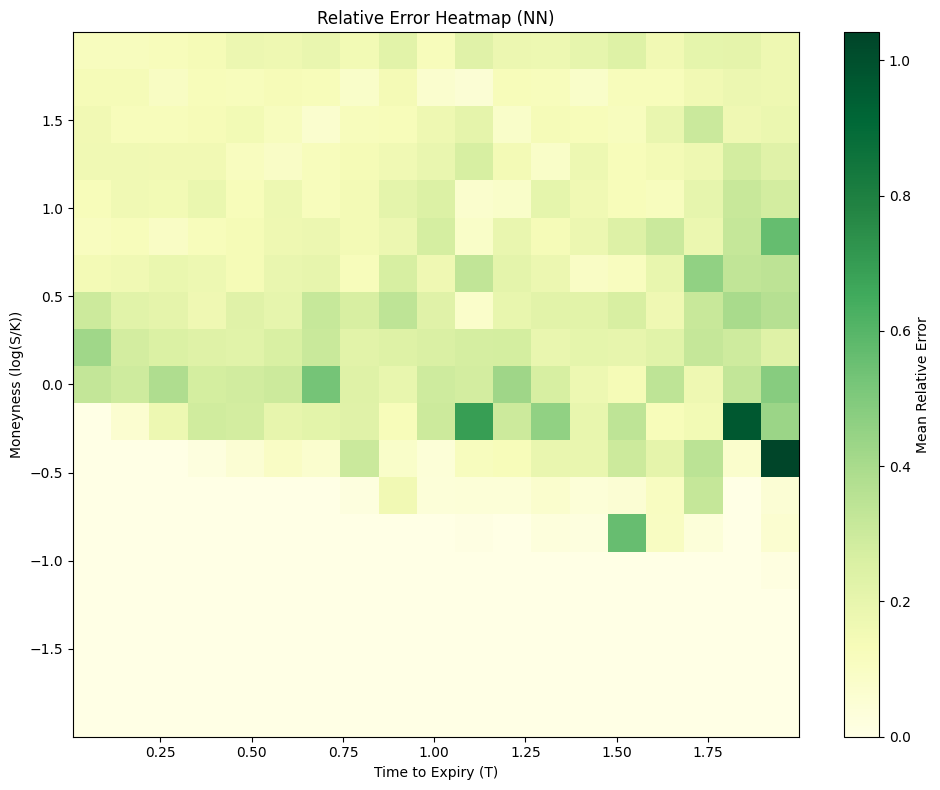


RAW (S, K) FEATURES, 5-128-128-64-1 MODEL VALIDATION REPORT
Mean Absolute Error (MAE):     0.163711
Root Mean Square Error (RMSE): 0.356941
Max Absolute Error:            3.601627
--------------------------------------------------
Mean Relative Error:           20.6429%
Median Relative Error:         14.8828%



In [5]:
X_test = X_test_raw
y_pred = predict(raw_model, X_test, norm_params, device="cpu")

eval("Raw (S, K) features, 5-128-128-64-1")

The non feature-engineered model's performance appears significantly worse than the model with feature engineering. More specifically, we measure mean absolute error at roughly 4x the baseline model (0.163 vs 0.047), and mean relative error (20.64% at 2.5x relative to our control (~8%). 

Furthermore, the disproportionately high error at tails previously mentioned in the control is observed to have increased significantly in magnitude, suggesting an even more pronounced heteroskedastic distribution. Across ITM options (log=moneyness > 1.0), the maximum absolute error is observed to increase by roughly 2x across the board, which is corroborated by the shape of our predicted vs. actual plot, which leads to a large fan-shaped distribution.

This is most likely due to the feature engineering fundamentally altering the nature of our problem. By passing log-moneyness directly into the MLP model, it's not necessary for our NN to learn the log-structure of $D_1, D_2$ directly. Furthermore, $D_1, D_2,$ and thus $C$ increases monotonically with log-moneyness, which results in a monotonically-increasing function that is easier for our MLP to capture.

As for relative error, although we still see a persistent increase in relative error with log-moneyness, the correlation with $T$ appears reversed, with error increasing as $T$ does, which may be a direction for further investigation.

### Model Architecture

Now we test the impact of model architecture, specifically testing a standard 4 --> 64 --> 64 --> 64 --> 1 (for breadth) and 4 --> 128 --> 128 --> 1 (for depth) against our current 4 --> 128 --> 128 --> 64 --> 1 architecture. Once again, data is consistent with the above tests.

In [6]:
cfg = cfg.replace(feature_mode="log-moneyness")

BREADTH_ARCHITECTURE = [4, 64, 64, 64, 1]
breadth_model = BSModel(layers=BREADTH_ARCHITECTURE)

DEPTH_ARCHITECTURE = [4, 128, 128, 1]
depth_model = BSModel(layers=DEPTH_ARCHITECTURE)

bundle = generate_bundle(cfg)

X_train, y_train = bundle.train.X, bundle.train.y_call
X_val, y_val = bundle.val.X, bundle.val.y_call

set_seed(42)

breadth_model, norm_params = train(
    X_train, y_train, X_val, y_val,
    device=device,
    patience=25,
    epochs=400,
    model=breadth_model
)

depth_model, _ = train(
    X_train, y_train, X_val, y_val,
    device=device,
    patience=25,
    epochs=400,
    model=depth_model
)

Epoch 0, Training Loss: 1.24238765, Eval Loss: 1.18580770
Epoch 10, Training Loss: 0.83061457, Eval Loss: 0.79208940
Epoch 20, Training Loss: 0.41723865, Eval Loss: 0.37475222
Epoch 30, Training Loss: 0.15002485, Eval Loss: 0.13551825
Epoch 40, Training Loss: 0.09623985, Eval Loss: 0.09181947
Epoch 50, Training Loss: 0.05235860, Eval Loss: 0.04998960
Epoch 60, Training Loss: 0.04242841, Eval Loss: 0.04135977
Epoch 70, Training Loss: 0.03702847, Eval Loss: 0.03613429
Epoch 80, Training Loss: 0.03194883, Eval Loss: 0.03128785
Epoch 90, Training Loss: 0.02844629, Eval Loss: 0.02781768
Epoch 100, Training Loss: 0.02527895, Eval Loss: 0.02462389
Epoch 110, Training Loss: 0.02223780, Eval Loss: 0.02157944
Epoch 120, Training Loss: 0.01937358, Eval Loss: 0.01874391
Epoch 130, Training Loss: 0.01665371, Eval Loss: 0.01601625
Epoch 140, Training Loss: 0.01405581, Eval Loss: 0.01345916
Epoch 150, Training Loss: 0.01179263, Eval Loss: 0.01124272
Epoch 160, Training Loss: 0.00989421, Eval Loss: 0.

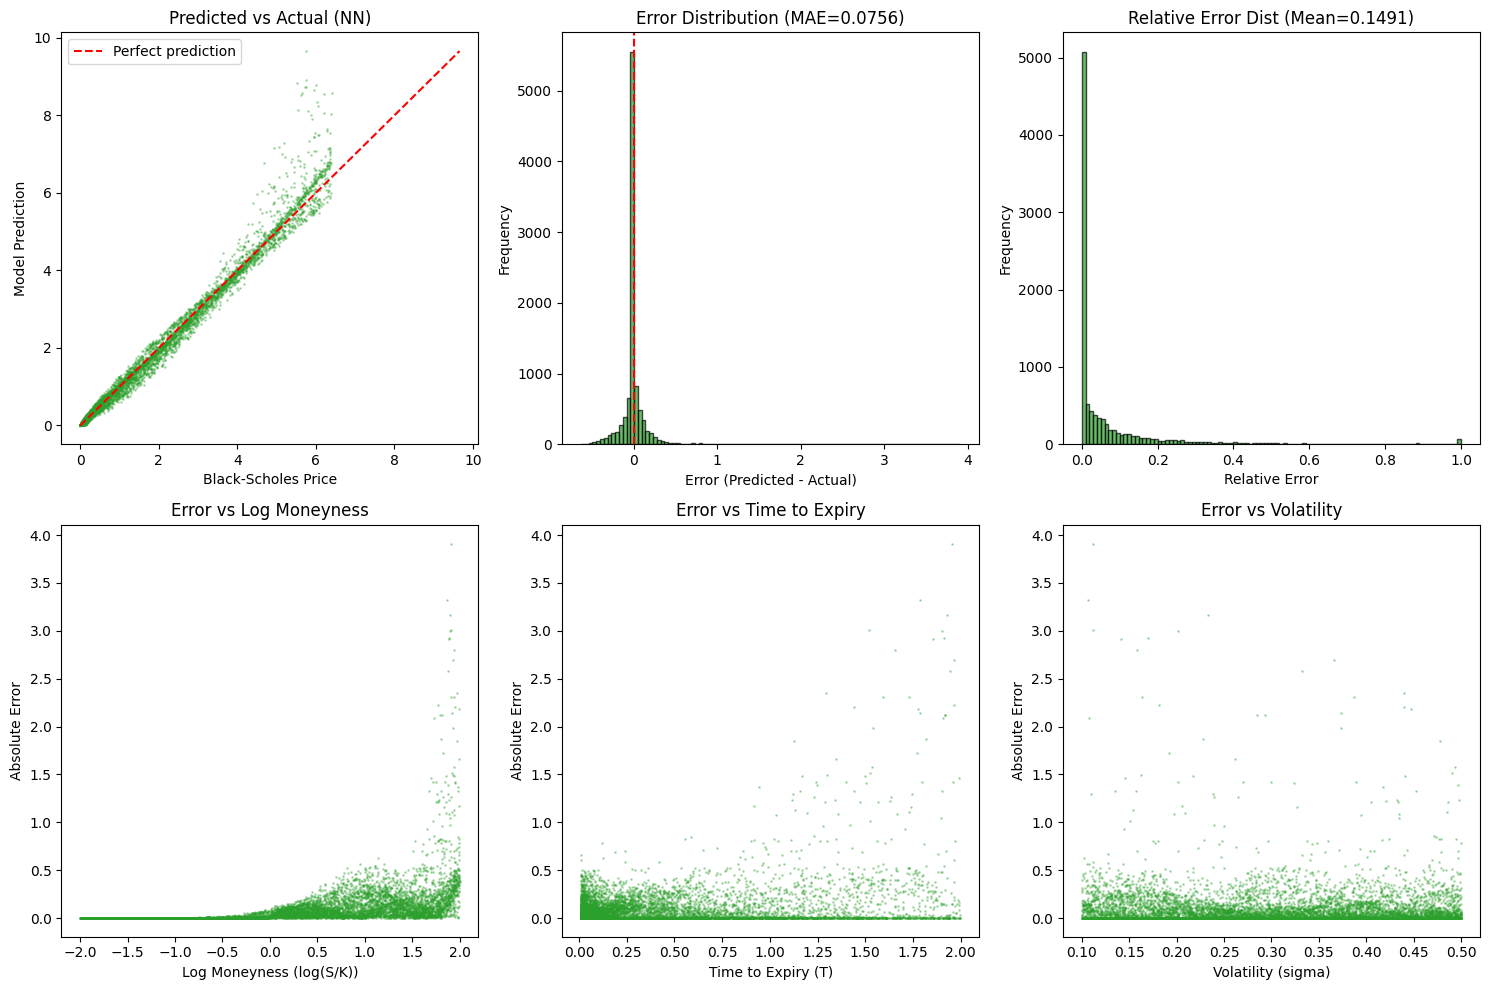

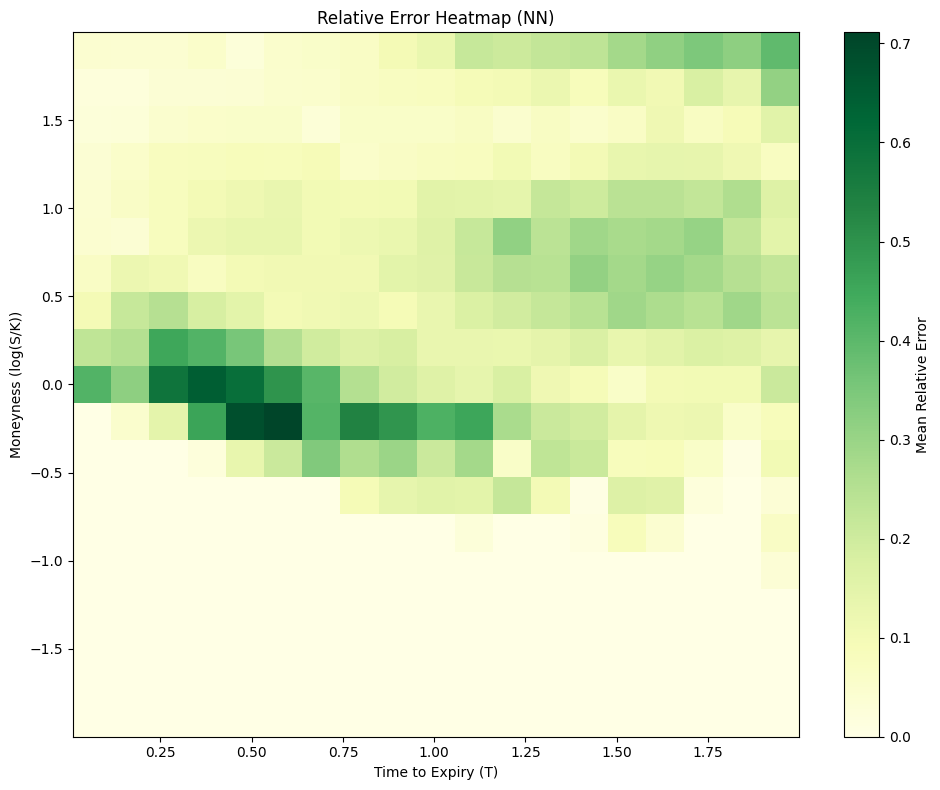


BREADTH-REDUCED, 4-64-64-64-1 MODEL VALIDATION REPORT
Mean Absolute Error (MAE):     0.075632
Root Mean Square Error (RMSE): 0.195927
Max Absolute Error:            3.911059
--------------------------------------------------
Mean Relative Error:           14.9123%
Median Relative Error:         6.7691%



In [7]:
X_test, _ = preprocess_test_data(X_test_raw)
y_pred = predict(breadth_model, X_test, norm_params, device="cpu")

eval("Breadth-reduced, 4-64-64-64-1")

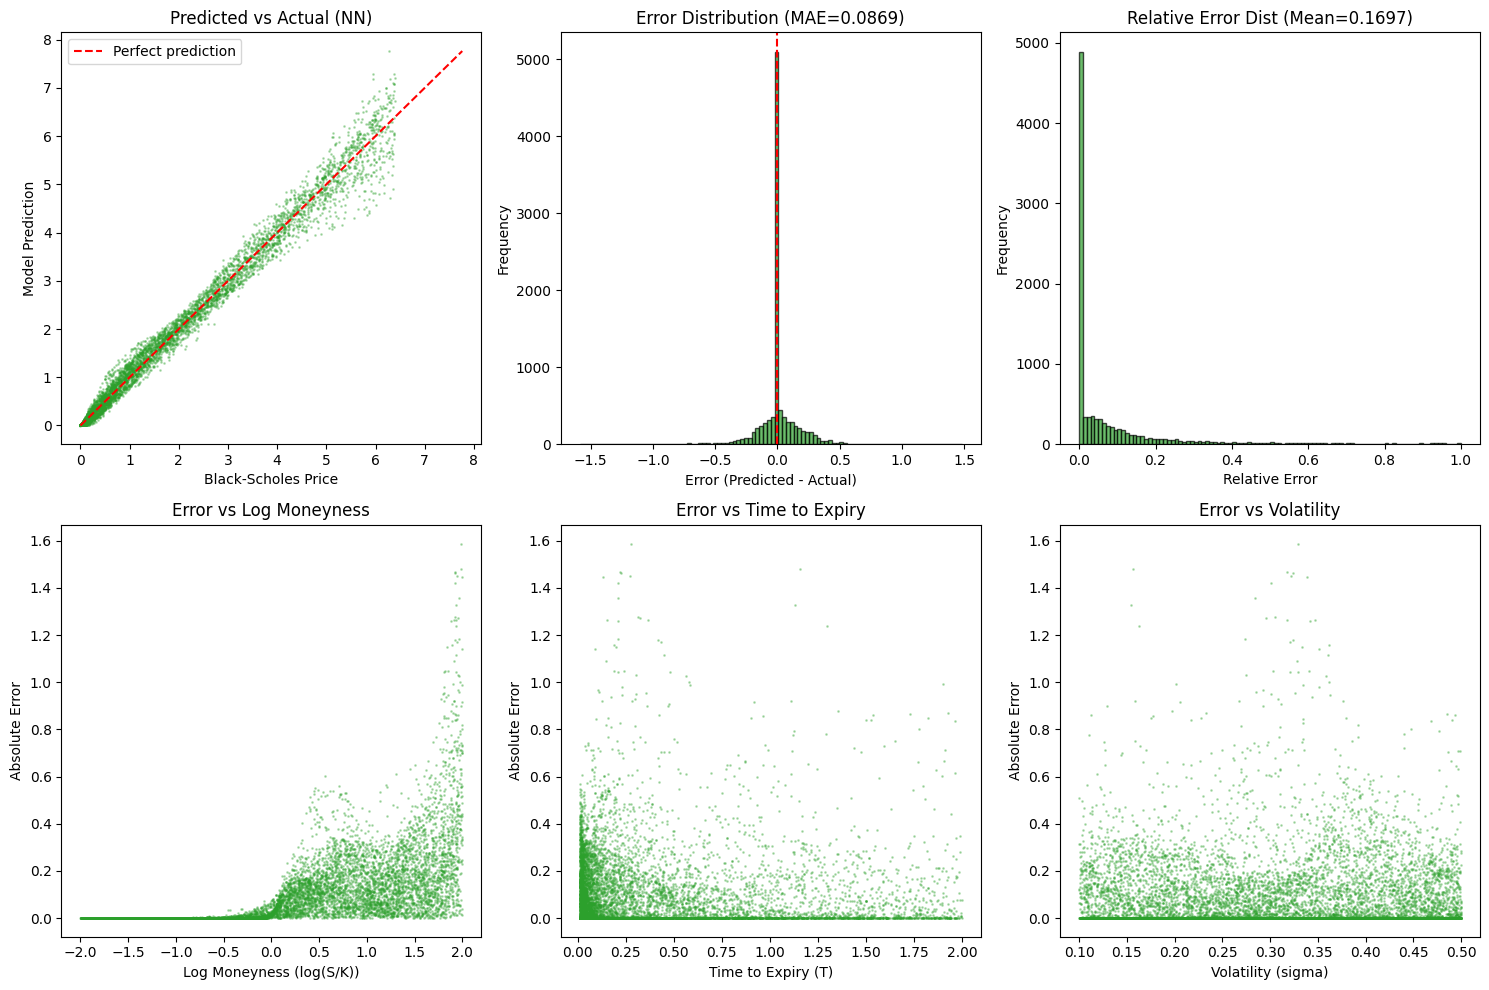

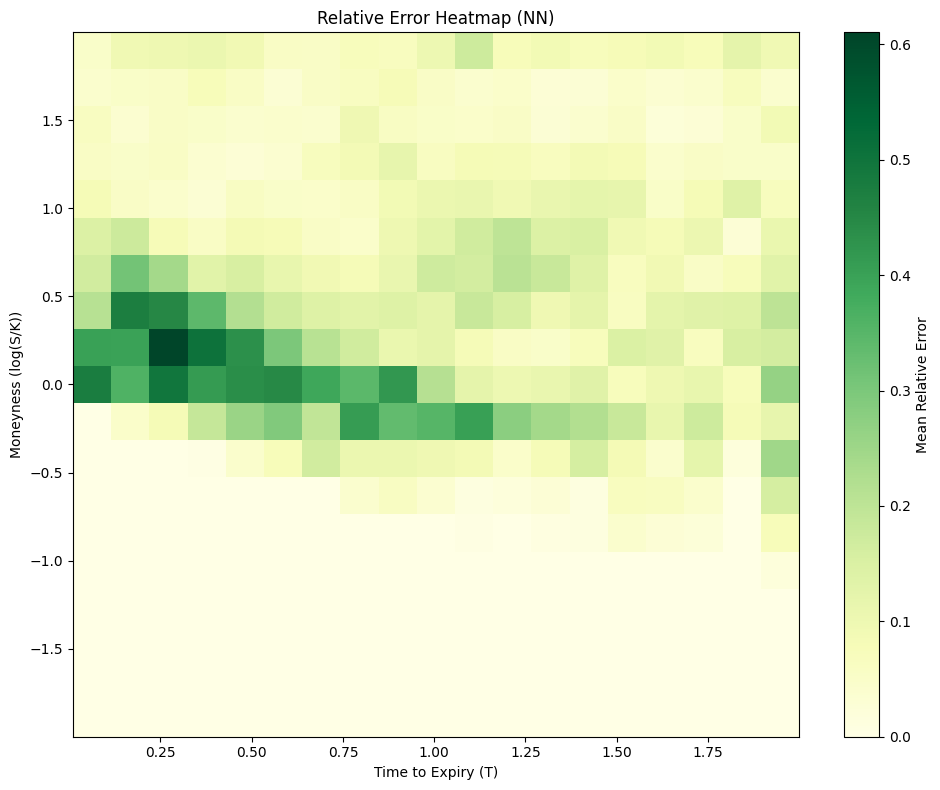


DEPTH-REDUCED, 4-128-128-1 MODEL VALIDATION REPORT
Mean Absolute Error (MAE):     0.086876
Root Mean Square Error (RMSE): 0.171218
Max Absolute Error:            1.587934
--------------------------------------------------
Mean Relative Error:           16.9713%
Median Relative Error:         9.1540%



In [8]:
X_test, _ = preprocess_test_data(X_test_raw)
y_pred = predict(depth_model, X_test, norm_params, device="cpu")

eval("Depth-reduced, 4-128-128-1")

We observe a marginal increase across all error metrics, suggesting a reduction in performance across all regimes. Against the base model, there exists roughly a 2x increase in error across all metrics (MAE and Mean Relative Error). The model appears to perform poorly on tails, but not meaningfully worse relative to the control. In particular, we see a persistent band of high relative error as moneyness increases, but particularly at low expiry times $T.$ The *shape* of this band corresponds to that of the control, but the magnitude of our error is increased by 2x, from 0.3 to 0.6. Hence, the *shape* of the error is the same, which suggest a structural limitation with the MLP rather than a training issue. However, broader, and wider model architectures were observed to meaningfully increase error metrics.

### Output Standardization 

Next is output standardization, specifically on `norm_params`, or (output - mean) / stdv. We also apply a log transform to our target of $\frac{S}{K},$ which is removed for this experiment.

Once again, data remains consistent with the tests above.

Epoch 0, Training Loss: 9.79706955, Eval Loss: 9.11969280
Epoch 10, Training Loss: 5.61297560, Eval Loss: 4.88302898
Epoch 20, Training Loss: 1.05258131, Eval Loss: 0.88256657
Epoch 30, Training Loss: 0.72398418, Eval Loss: 0.62440717
Epoch 40, Training Loss: 0.39926210, Eval Loss: 0.33984420
Epoch 50, Training Loss: 0.21905865, Eval Loss: 0.19661774
Epoch 60, Training Loss: 0.14091361, Eval Loss: 0.13534607
Epoch 70, Training Loss: 0.09629792, Eval Loss: 0.08797008
Epoch 80, Training Loss: 0.07122383, Eval Loss: 0.06820756
Epoch 90, Training Loss: 0.05716465, Eval Loss: 0.05488288
Epoch 100, Training Loss: 0.04471608, Eval Loss: 0.04300006
Epoch 110, Training Loss: 0.03527840, Eval Loss: 0.03362566
Epoch 120, Training Loss: 0.02806545, Eval Loss: 0.02652959
Epoch 130, Training Loss: 0.02234103, Eval Loss: 0.02101204
Epoch 140, Training Loss: 0.01770772, Eval Loss: 0.01653044
Epoch 150, Training Loss: 0.01394228, Eval Loss: 0.01293450
Epoch 160, Training Loss: 0.01090131, Eval Loss: 0.

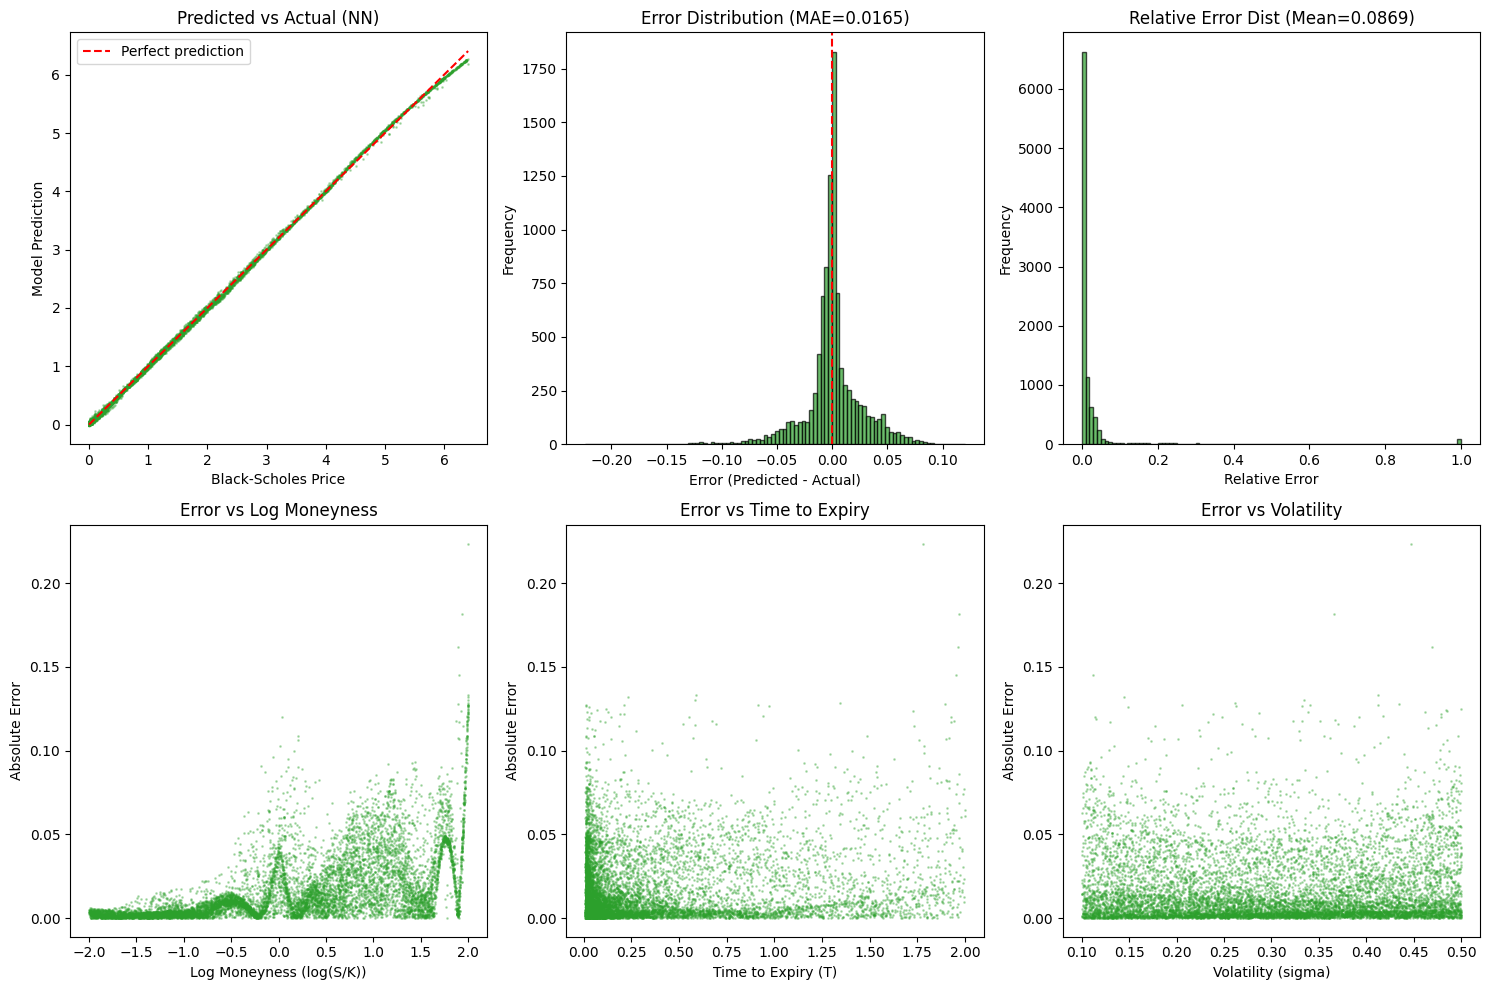

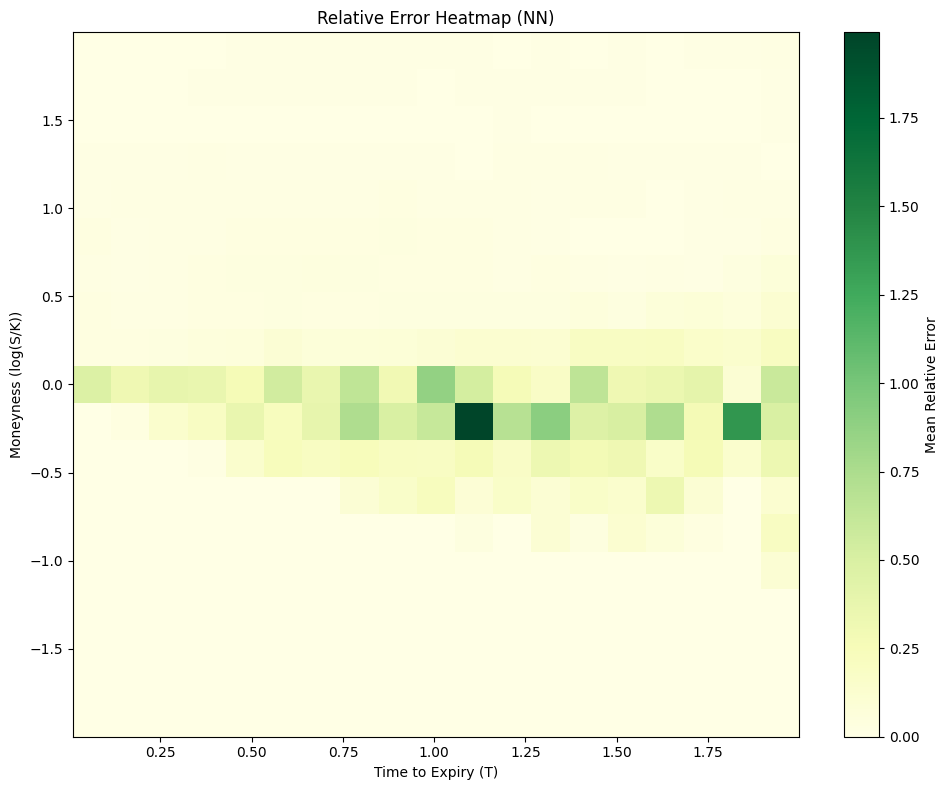


NO LOG TRANSFORM, STANDARDIZATION MODEL VALIDATION REPORT
Mean Absolute Error (MAE):     0.016488
Root Mean Square Error (RMSE): 0.026117
Max Absolute Error:            0.223561
--------------------------------------------------
Mean Relative Error:           8.6891%
Median Relative Error:         1.5276%



In [12]:
set_seed(42)

destandardized_model, norm_params = train(
    X_train, y_train, X_val, y_val,
    device=device,
    patience=25,
    epochs=400,
    standardize=False
)

y_pred = predict(destandardized_model, X_test, norm_params, device="cpu")

eval("No log transform, standardization")

**How is it almost a perfect fit?**

It appears as if the model might be fighting its own preprocessing. Standardization and log-transform may not be necessary for an analytic closed-form function like Black-Scholes. The data preprocessing as implemented on the control is only beneficial if targets vary significantly over feature space, or if our data is heavily skewed, of which neither is the case.

Yet standardization might remain a good practice for future work, particularly when training datasets are noisy or increasingly varied.

### Hybrid MSE Loss

Our final experiment removes our hybrid MSE loss (linear interpolation over MSE and $y \cdot$ MSE, with $\alpha \neq 0, 1$), and replaces it with a pure MSE loss approach. 

Epoch 0, Training Loss: 0.98770624, Eval Loss: 0.91121954
Epoch 10, Training Loss: 0.31267682, Eval Loss: 0.25883627
Epoch 20, Training Loss: 0.14492129, Eval Loss: 0.12646219
Epoch 30, Training Loss: 0.08265361, Eval Loss: 0.08265010
Epoch 40, Training Loss: 0.05462459, Eval Loss: 0.05330124
Epoch 50, Training Loss: 0.04443021, Eval Loss: 0.04295145
Epoch 60, Training Loss: 0.03642037, Eval Loss: 0.03537941
Epoch 70, Training Loss: 0.03010192, Eval Loss: 0.02874754
Epoch 80, Training Loss: 0.02439204, Eval Loss: 0.02328688
Epoch 90, Training Loss: 0.01925739, Eval Loss: 0.01816861
Epoch 100, Training Loss: 0.01513422, Eval Loss: 0.01424691
Epoch 110, Training Loss: 0.01222234, Eval Loss: 0.01144121
Epoch 120, Training Loss: 0.01021696, Eval Loss: 0.00958369
Epoch 130, Training Loss: 0.00869106, Eval Loss: 0.00813952
Epoch 140, Training Loss: 0.00748139, Eval Loss: 0.00699887
Epoch 150, Training Loss: 0.00652705, Eval Loss: 0.00610666
Epoch 160, Training Loss: 0.00574098, Eval Loss: 0.

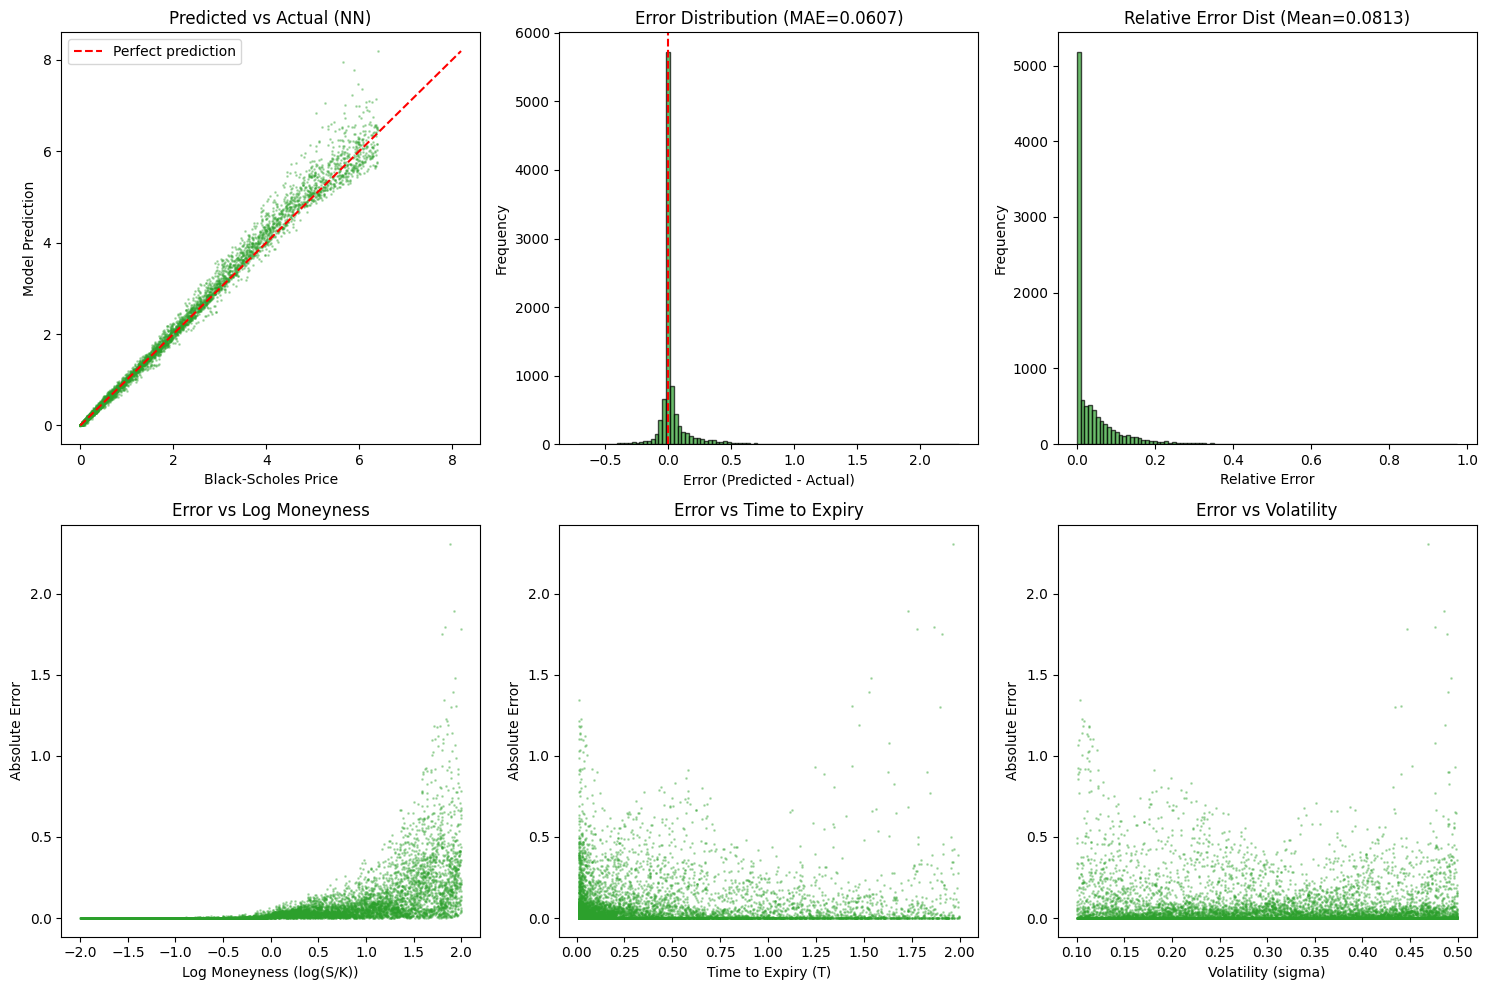

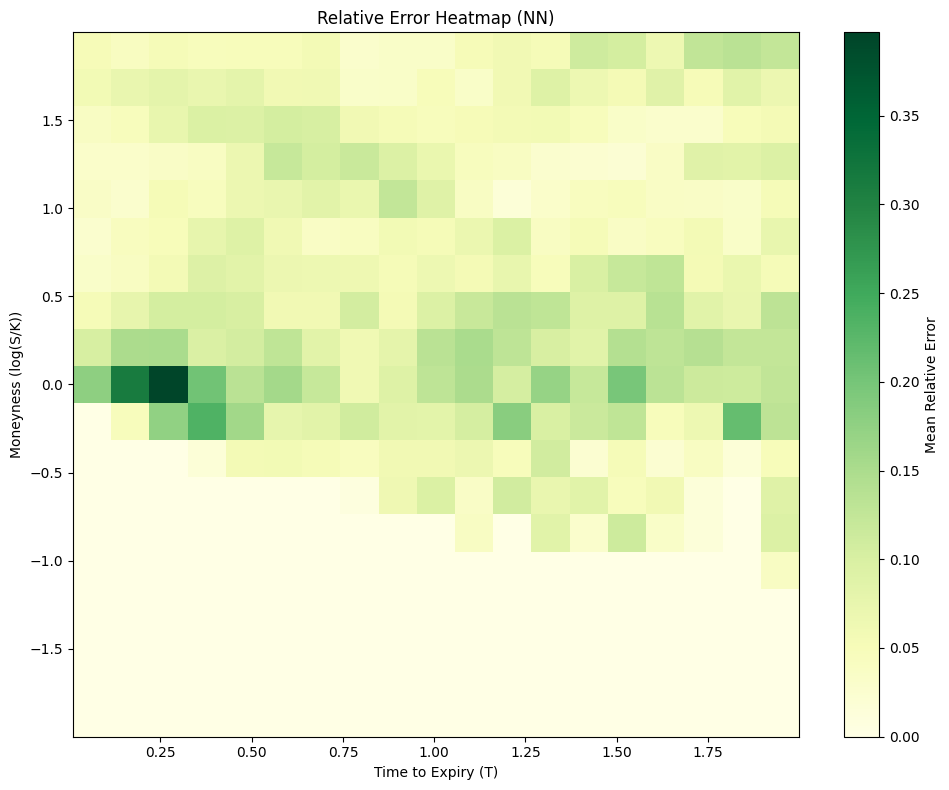


NO HYBRID LOSS MODEL VALIDATION REPORT
Mean Absolute Error (MAE):     0.060656
Root Mean Square Error (RMSE): 0.149666
Max Absolute Error:            2.310344
--------------------------------------------------
Mean Relative Error:           8.1276%
Median Relative Error:         4.9378%



In [13]:
set_seed(42)

no_log_model, norm_params = train(
    X_train, y_train, X_val, y_val,
    device=device,
    patience=25,
    epochs=400,
    hybrid_loss=False
)

y_pred = predict(no_log_model, X_test, norm_params, device="cpu")

eval("No Hybrid Loss")

Our performance is actually very similar to the standard base model, at least in terms of headline metrics. More interestingly, our error metrics, particularly in **absolute error** at tails decreased significantly, which is most likely due to the loss function now prioritizing only base MSE. 

This is likely due to the choice of value $y=\frac{C}{K}$ for evaluation. While the model is trained on log space, the exponential denormalization applied to its outputs for evaluation heavily punishes errors in ITM. In our control, the $y-$weighted MSE would account for this increase in error, but now, standard MSE struggles to capture values at such a regime.